# Example 6: User-drawn trib areas and arbitrary loads

The drawing from papermodels' Example 6: beams with trib areas drawn by the user and loading
areas of arbitrary shape. No collector behaviour is assigned, so there are no joist arrays.
The load on each beam follows the shape of the loading areas.

In [1]:
%matplotlib inline
import sys
import warnings
from decimal import Decimal

import pandas as pd
from papermodels.datatypes.geometry_graph import GeometryGraph
from papermodels.datatypes.joist_models import JoistArrayModel
from loadtracer.load_tracer import LoadTracer

sys.path.insert(0, "..")
from helpers import (
    bottom_members,
    compare_modes,
    load_check,
    load_table,
    occupancies_in,
    quietly,
    reaction_table,
)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_rows = 40

## 1. Build the graph (papermodels)

In [2]:
pdf_path = "user-applied-trib-area-arbitrary-loads.pdf"

In [3]:
# No collector behaviour: the beams carry the trib areas drawn by the user
graph = GeometryGraph.from_pdf_file(pdf_path, scale=Decimal(1 / 72 * 4))

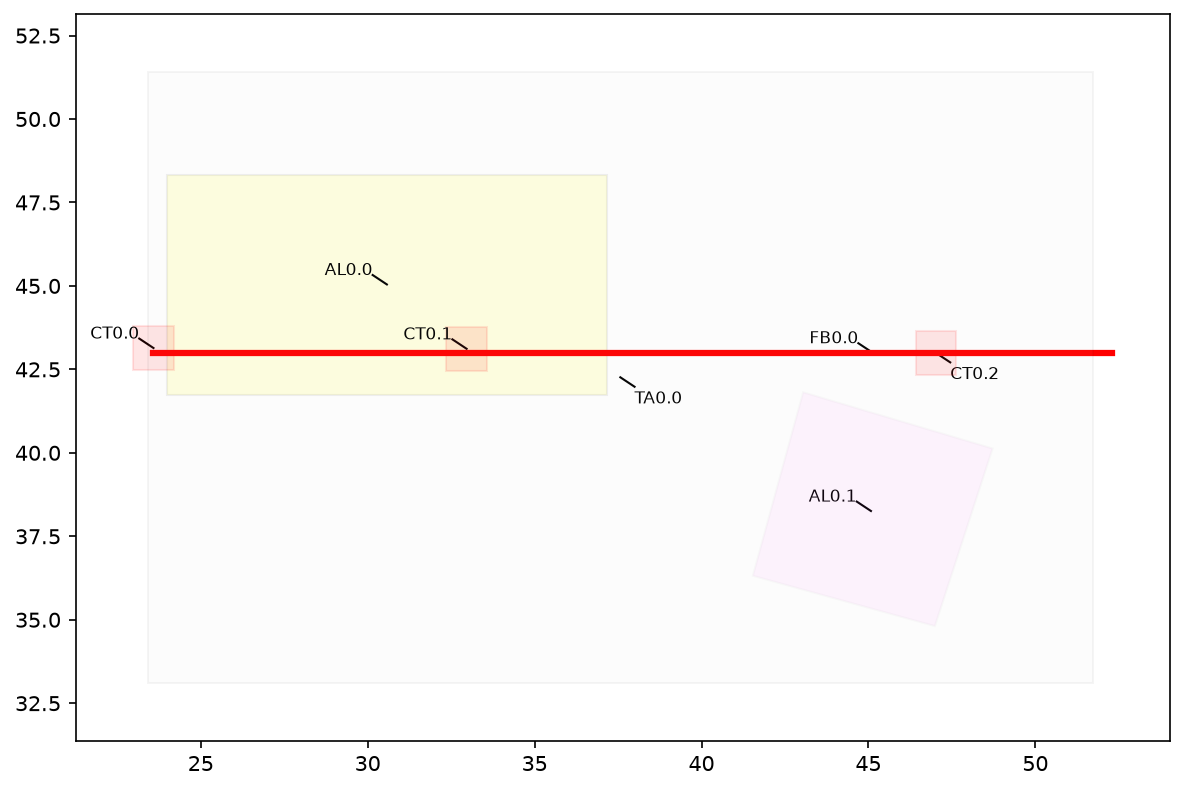

In [4]:
graph.plot_annotations(0)

## 2. Occupancies

loadtracer needs the loads of each occupancy in the drawing, as pressures by load case.
These are the occupancies that the loading areas use:

In [5]:
occupancies_in(graph)

['a', 'f']

The drawing is in feet, so these pressures (psf) give loads in lb/ft and lb.

In [6]:
occupancies = {
    "a": {"D": 10.0, "L": 40.0},
    "f": {"D": 15.0, "L": 50.0},
}

## 3. Run loadtracer

Every element is analysed from the top of the graph down. Only the graph and the occupancies
are needed; element heights and floor elevations are not inputs. `artifacts/` receives the
analysis models (`models.json`) and the reactions (`reaction_forces.json`).

In [7]:
lt = LoadTracer(geometry_graph=graph, occupancies=occupancies)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    quietly(lt.execute_analyses, artifacts_dir="artifacts")

print(f"{len(lt.reactions)} members analysed, {len(lt.errors)} errors")
for w in caught:
    print(f"{type(w.message).__name__}: {w.message}")

4 members analysed, 0 errors


All of the load applied to the building reaches the bottom of the graph:

In [8]:
load_check(lt)

,applied,at the bottom
D,376.01,376.01
L,"1,303.54","1,303.54"


`lt.issues` lists input that loadtracer corrected so that the rundown could continue
(for example, load drawn past the end of a member, which is moved to the member end):

In [9]:
{tag: issues for tag, issues in lt.issues.items()}

{}

## 4. One member, end to end: `FB0.0`

`FB0.0` carries loads projected from irregular loading areas. There are no joists, so there
is nothing to convert: `converted_joist_loads()` is empty and both joist modes give the same
result.

In [10]:
pd.DataFrame(lt.converted_joist_loads("FB0.0"))

""


The loads on `FB0.0` after expansion, by load case:

In [11]:
load_table(lt, "FB0.0")

,kind,source,case,start,end,w_start / P,w_end,total,profile
0,distributed,occupancy: f,D,0.19,6.52,47.48,47.48,300.74,
1,distributed,occupancy: f,L,0.19,6.52,158.27,158.27,"1,002.47",
2,distributed,occupancy: a,D,8.62,9.34,0.00,28.38,10.26,
3,distributed,occupancy: a,L,8.62,9.34,0.00,113.51,41.03,
4,distributed,occupancy: a,D,9.34,11.24,28.38,28.00,53.39,
5,distributed,occupancy: a,L,9.34,11.24,113.51,112.00,213.56,
6,distributed,occupancy: a,D,11.24,12.07,28.00,0.00,11.62,
7,distributed,occupancy: a,L,11.24,12.07,112.00,0.00,46.48,


The loads in the Pynite model of `FB0.0`:

In [12]:
member = lt.models["FB0.0"]["members"]["FB0.0"]
pd.DataFrame(member["DistLoads"] + member["PtLoads"])

,0,1,2,3,4,5,6
0,FY,47.48,47.48,0.19,6.52,D,False
1,FY,158.27,158.27,0.19,6.52,L,False
2,FY,0.00,28.38,8.62,9.34,D,False
3,FY,0.00,113.51,8.62,9.34,L,False
4,FY,28.38,28.00,9.34,11.24,D,False
5,FY,113.51,112.00,9.34,11.24,L,False
6,FY,28.00,0.00,11.24,12.07,D,False
7,FY,112.00,0.00,11.24,12.07,L,False


The reactions of `FB0.0` (positive downwards on the supports):

In [13]:
reaction_table(lt, ["FB0.0"])

D      L
member support              
FB0.0  0        73.67 242.61
       1       239.45 810.02
       2        62.90 250.91

## 5. Joist loads as point loads or distributed loads

With `joist_loads="point"` each joist reaction is applied as a point load, which is the most
detailed representation. The total load is the same either way. Individual reactions are the
same for uniform joist reactions and differ more the more the joist reactions vary; arrays that
vary by 2:1 or more are listed in the warnings in section 3. For those, check the point load
results.

In [14]:
lt_point = LoadTracer(geometry_graph=graph, occupancies=occupancies, joist_loads="point")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    quietly(lt_point.execute_analyses)

pd.concat({"point": load_check(lt_point)["at the bottom"], "distributed": load_check(lt)["at the bottom"]}, axis=1)

,point,distributed
D,376.01,376.01
L,"1,303.54","1,303.54"


In [15]:
compare_modes(lt_point, lt, ["FB0.0"])

point        distributed        difference     
                    D      L           D      L          D    L
member support                                                 
FB0.0  0        73.67 242.61       73.67 242.61       0.00 0.00
       1       239.45 810.02      239.45 810.02       0.00 0.00
       2        62.90 250.91       62.90 250.91       0.00 0.00

## 6. Reactions at the bottom

The loads delivered to the elements at the bottom of the graph (the foundation):

In [16]:
reaction_table(lt, bottom_members(lt))

,,D,L
member,support,,
CT0.0,0,73.67,242.61
CT0.1,0,239.45,810.02
CT0.2,0,62.90,250.91
